# Data exploration

Looking at the Food.com dataset before designing the graph.

Source: https://www.kaggle.com/datasets/shuyangli94/food-com-recipes-and-user-interactions

Files are in data/raw (not on github, too big):
- RAW_recipes.csv: one row per recipe
- RAW_interactions.csv: one row per review/rating of a recipe by a user

In [1]:
import ast
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"

## 1. Load

In [2]:
recipes = pd.read_csv(RAW / "RAW_recipes.csv")
interactions = pd.read_csv(RAW / "RAW_interactions.csv")
print(recipes.shape, interactions.shape)

(231637, 12) (1132367, 5)


In [3]:
recipes.head(3)

,name,id,minutes,contributor_id,submitted,tags,nutrition,n_steps,steps,description,ingredients,n_ingredients
0,arriba baked winter squash mexican style,137739,55,47892,2005-09-16,"['60-minutes-or-less', 'time-to-make', 'course...","[51.5, 0.0, 13.0, 0.0, 2.0, 0.0, 4.0]",11,"['make a choice and proceed with recipe', 'dep...",autumn is my favorite time of year to cook! th...,"['winter squash', 'mexican seasoning', 'mixed ...",7
1,a bit different breakfast pizza,31490,30,26278,2002-06-17,"['30-minutes-or-less', 'time-to-make', 'course...","[173.4, 18.0, 0.0, 17.0, 22.0, 35.0, 1.0]",9,"['preheat oven to 425 degrees f', 'press dough...",this recipe calls for the crust to be prebaked...,"['prepared pizza crust', 'sausage patty', 'egg...",6
2,all in the kitchen chili,112140,130,196586,2005-02-25,"['time-to-make', 'course', 'preparation', 'mai...","[269.8, 22.0, 32.0, 48.0, 39.0, 27.0, 5.0]",6,"['brown ground beef in large pot', 'add choppe...",this modified version of 'mom's' chili was a h...,"['ground beef', 'yellow onions', 'diced tomato...",13


In [4]:
interactions.head(3)

,user_id,recipe_id,date,rating,review
0,38094,40893,2003-02-17,4,Great with a salad. Cooked on top of stove for...
1,1293707,40893,2011-12-21,5,"So simple, so delicious! Great for chilly fall..."
2,8937,44394,2002-12-01,4,This worked very well and is EASY. I used not...


## 2. Missing values

In [5]:
recipes.isna().sum()

name                 1
id                   0
minutes              0
contributor_id       0
submitted            0
tags                 0
nutrition            0
n_steps              0
steps                0
description       4979
ingredients          0
n_ingredients        0
dtype: int64

In [6]:
interactions.isna().sum()

user_id        0
recipe_id      0
date           0
rating         0
review       169
dtype: int64

Takeaway: almost nothing missing. 1 recipe without a name, ~5k without description, 169 reviews without text. fine.

## 3. Ids

In [7]:
print("duplicate recipe ids:", recipes["id"].duplicated().sum())
print("duplicate recipe names:", recipes["name"].duplicated().sum())
print("same user rating same recipe twice:", interactions.duplicated(["user_id", "recipe_id"]).sum())
print("interactions with unknown recipe:", (~interactions["recipe_id"].isin(recipes["id"])).sum())
print("recipes with no interaction:", (~recipes["id"].isin(interactions["recipe_id"])).sum())

duplicate recipe ids: 0
duplicate recipe names: 1451
same user rating same recipe twice: 0
interactions with unknown recipe: 0
recipes with no interaction: 0


In [8]:
contributors = recipes["contributor_id"].drop_duplicates()
print("users:", interactions["user_id"].nunique())
print("contributors:", contributors.size)
print("contributors who also review:", contributors.isin(interactions["user_id"]).sum())

users: 226570
contributors: 27926
contributors who also review: 17777


Takeaways:
- recipe id is unique, so it can be a unique constraint. name is not unique (1451 dupes).
- a user rates a recipe at most once.
- every interaction points to a real recipe, and every recipe has at least one interaction.
- most contributors also write reviews, so contributor_id and user_id are the same thing (food.com accounts). probably one User node for both.

## 4. List columns

tags, nutrition, steps and ingredients look like lists but they are strings.

In [9]:
type(recipes.loc[0, 'ingredients']), recipes.loc[0, 'ingredients'][:80]

(str,
 "['winter squash', 'mexican seasoning', 'mixed spice', 'honey', 'butter', 'olive ")

In [10]:
for col in ["tags", "nutrition", "steps", "ingredients"]:
    recipes[col] = recipes[col].map(ast.literal_eval)

print(recipes.loc[0, "ingredients"][:5])
print((recipes["ingredients"].map(len) == recipes["n_ingredients"]).all())
print((recipes["steps"].map(len) == recipes["n_steps"]).all())

['winter squash', 'mexican seasoning', 'mixed spice', 'honey', 'butter']
True
True


Takeaway: ast.literal_eval works. n_ingredients and n_steps match the list lengths.

## 5. Ingredients

In [11]:
ingredient_counts = recipes["ingredients"].explode().value_counts()
print("distinct ingredients:", ingredient_counts.size)
print("used only once:", (ingredient_counts == 1).sum())
ingredient_counts.head(20)

distinct ingredients: 14942
used only once: 3546


ingredients
salt                 85746
butter               54975
sugar                44535
onion                39065
water                34914
eggs                 33761
olive oil            32822
flour                26266
milk                 25786
garlic cloves        25748
pepper               22319
brown sugar          18655
garlic               18087
all-purpose flour    17659
baking powder        17504
egg                  17304
salt and pepper      15415
parmesan cheese      14807
lemon juice          14233
baking soda          14099
Name: count, dtype: int64

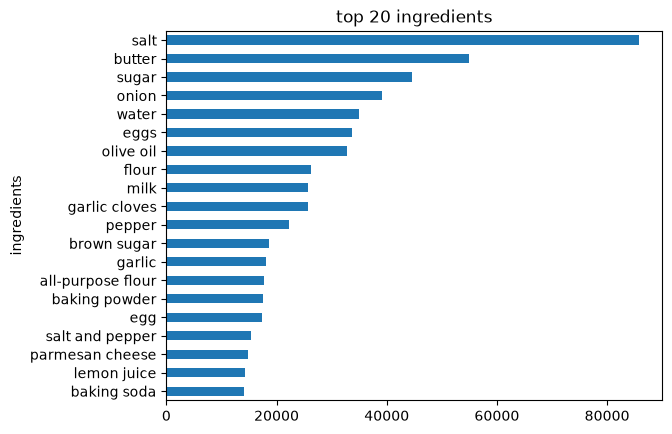

In [12]:
ingredient_counts.head(20).sort_values().plot.barh(title="top 20 ingredients")
plt.show()

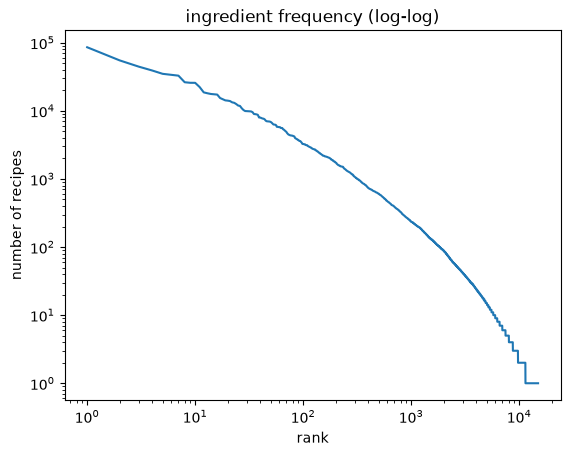

In [13]:
plt.loglog(range(1, ingredient_counts.size + 1), ingredient_counts.values)
plt.title("ingredient frequency (log-log)")
plt.xlabel("rank")
plt.ylabel("number of recipes")
plt.show()

In [14]:
print([name for name in ingredient_counts.index if "egg" in name][:12])
print([name for name in ingredient_counts.index if "salt" in name][:12])

['eggs', 'egg', 'egg whites', 'egg yolks', 'egg white', 'egg yolk', 'hard-boiled eggs', 'eggplant', 'egg noodles', 'parmigiano-reggiano cheese', 'egg substitute', 'eggplants']
['salt', 'salt and pepper', 'unsalted butter', 'kosher salt', 'sea salt', 'salt & freshly ground black pepper', 'garlic salt', 'seasoning salt', 'salt & pepper', 'coarse salt', 'salt and black pepper', 'celery salt']


Takeaways:
- ingredients are shared by lots of recipes (salt is in 86k), so they should be nodes, not a list on the recipe.
- names are messy: egg / eggs, "salt and pepper" is 2 ingredients, garlic vs garlic cloves, eggplant matches "egg". need some cleaning.
- long tail, ~3.5k ingredients used once (typos, brands).
- salt, butter, sugar are in everything. they might mess up similarity algorithms later.

## 6. Tags

In [15]:
tag_counts = recipes["tags"].explode().value_counts()
print("distinct tags:", tag_counts.size)
(tag_counts / len(recipes) * 100).round(1).head(15)

distinct tags: 552


tags
preparation           99.5
time-to-make          97.3
course                94.2
main-ingredient       73.6
dietary               71.3
easy                  54.4
occasion              49.3
cuisine               39.4
low-in-something      37.0
main-dish             31.0
equipment             30.4
60-minutes-or-less    30.2
number-of-servings    25.4
meat                  24.2
30-minutes-or-less    23.8
Name: count, dtype: float64

In [16]:
(tag_counts / len(recipes) * 100).round(1)[
    ["vegetarian", "vegan", "gluten-free", "desserts", "main-dish", "italian", "mexican", "30-minutes-or-less", "healthy"]
]

tags
vegetarian            15.4
vegan                  4.3
gluten-free            2.5
desserts              18.7
main-dish             31.0
italian                3.2
mexican                2.9
30-minutes-or-less    23.8
healthy               17.4
Name: count, dtype: float64

Takeaways:
- top tags (preparation, time-to-make, course...) are on almost every recipe, useless. drop them.
- some tags repeat other columns (15-minutes-or-less = minutes, 5-ingredients-or-less = n_ingredients).
- useful ones are different kinds: diet, cuisine, course, occasion.
- tags as nodes or as properties? decide in step 15.

## 7. Minutes and nutrition

In [17]:
print(recipes["minutes"].describe())
print("0 minutes:", (recipes["minutes"] == 0).sum())
print("more than a day:", (recipes["minutes"] > 1440).sum())

count    2.316370e+05
mean     9.398546e+03
std      4.461963e+06
min      0.000000e+00
25%      2.000000e+01
50%      4.000000e+01
75%      6.500000e+01
max      2.147484e+09
Name: minutes, dtype: float64
0 minutes: 1094
more than a day: 2000


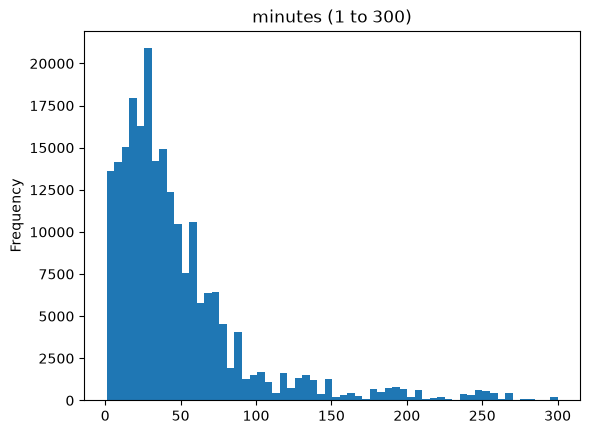

In [18]:
recipes.loc[recipes["minutes"].between(1, 300), "minutes"].plot.hist(bins=60, title="minutes (1 to 300)")
plt.show()

In [19]:
nutrition = pd.DataFrame(
    recipes["nutrition"].tolist(),
    columns=["calories", "total_fat", "sugar", "sodium", "protein", "saturated_fat", "carbs"],
)
nutrition.describe().round(1)

,calories,total_fat,sugar,sodium,protein,saturated_fat,carbs
count,231637.0,231637.0,231637.0,231637.0,231637.0,231637.0,231637.0
mean,473.9,36.1,84.3,30.1,34.7,45.6,15.6
std,1189.7,77.8,800.1,132.0,58.5,98.2,81.8
min,0.0,0.0,0.0,0.0,0.0,0.0,0.0
25%,174.4,8.0,9.0,5.0,7.0,7.0,4.0
50%,313.4,20.0,25.0,14.0,18.0,23.0,9.0
75%,519.7,41.0,68.0,33.0,51.0,52.0,16.0
max,434360.2,17183.0,362729.0,29338.0,6552.0,10395.0,36098.0


Takeaways:
- minutes has crazy values. max is 2147483647 (max int, basically a placeholder) and 1094 recipes have 0. set those to null.
- nutrition is 7 numbers: calories, then % daily value for fat, sugar, sodium, protein, sat fat, carbs.
- they belong to one recipe, so properties on Recipe. some huge values (434k calories), cap or null them.

## 8. Ratings and users

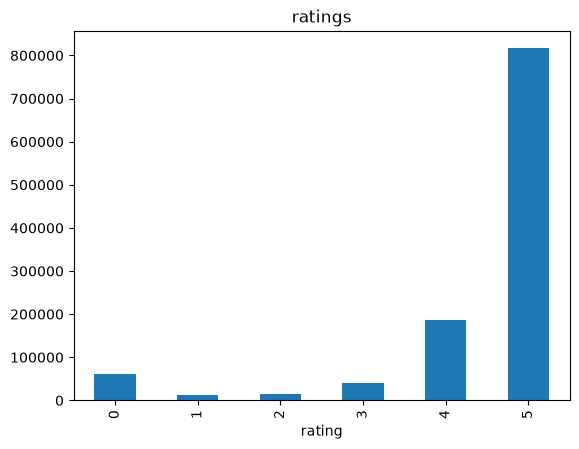

rating
0     5.4
1     1.1
2     1.2
3     3.6
4    16.5
5    72.1
Name: proportion, dtype: float64

In [20]:
interactions["rating"].value_counts().sort_index().plot.bar(title="ratings")
plt.show()
(interactions["rating"].value_counts(normalize=True).sort_index() * 100).round(1)

In [21]:
per_user = interactions.groupby("user_id").size()
per_recipe = interactions.groupby("recipe_id").size()
print(per_user.describe())
print(per_recipe.describe())
print("users with only 1 interaction:", (per_user == 1).sum())
print("users with 5 or more:", (per_user >= 5).sum())

count    226570.000000
mean          4.997868
std          49.663111
min           1.000000
25%           1.000000
50%           1.000000
75%           2.000000
max        7671.000000
dtype: float64
count    231637.000000
mean          4.888541
std          17.532481
min           1.000000
25%           1.000000
50%           2.000000
75%           4.000000
max        1613.000000
dtype: float64
users with only 1 interaction: 166256
users with 5 or more: 23086


Takeaways:
- rating 0 = review without a rating (5% of rows), not a bad rating. don't count it in averages.
- 72% of ratings are 5, so average rating doesn't say much. number of ratings is probably more useful.
- 73% of users only rated once. for recommendations keep users with 5+ ratings maybe.
- rating and date belong to the user-recipe pair, so they go on the RATED relationship.

## 9. Summary

- ~231k recipes, ~1.1M interactions, ~227k users, ~15k ingredient names, 552 tags
- unique constraints on Recipe.id and User.id, Recipe.name only an index
- Ingredient as nodes, needs name cleaning
- tags: drop the useless ones, nodes vs properties to decide
- one User for contributors and reviewers
- rating and date on RATED, rating 0 = no rating
- minutes and nutrition on Recipe, clean the outliers
- filter users with few ratings for recommendations

first idea for the graph (to discuss in step 15):

    (:User)-[:SUBMITTED]->(:Recipe)
    (:User)-[:RATED {rating, date}]->(:Recipe)
    (:Recipe)-[:CONTAINS]->(:Ingredient)
    (:Recipe)-[:HAS_TAG]->(:Tag)